# Assignment 1 — EDA & Baselines
**Competition:** [PhysioNet – Digitization of ECG Images](https://www.kaggle.com/competitions/physionet-ecg-image-digitization) (closed 2026-01-22)
**Task:** reconstruct 12-lead ECG time series (mV) from images of paper ECGs — scans, phone photos, stains, mold, laptop-screen photographs.

Deliverable: exploratory data analysis + baseline implementations (written from scratch in `src/`) + evaluation with the official competition metric (vendored in `src/metric.py`).

Run top-to-bottom; Section 0 handles Colab bootstrap automatically.

In [ ]:
import os, sys, getpass, zipfile, shutil
REPO, GUSER = "GROUP43_CENG313", "mmilesmorales"

# 1) code — PRIVATE repo (you must be a collaborator)
#    * Best: open this notebook via the Colab-GitHub link — Colab clones the
#      private repo for your logged-in GitHub account, no token needed.
#    * If this prompt appears (bare notebook upload), paste a GitHub token with
#      read access to the repo. It is used for this one clone and never stored.
inside_project = os.path.isdir("src") and os.path.isfile("src/metric.py")
if not inside_project and not os.path.isdir(REPO):
    print("cloning the private repository (collaborator access required)…")
    tok = getpass.getpass("GitHub token (input hidden, not stored): ")
    os.system(f'git clone -q https://{tok}@github.com/{GUSER}/{REPO}.git')
    if not os.path.isdir(REPO):
        raise RuntimeError("clone failed — verify token + collaborator access")
    if os.path.basename(os.getcwd()) != REPO:
        os.chdir(REPO)
elif inside_project:
    print("already inside the project folder — no clone needed")
sys.path.insert(0, "src")

# 2) data — public Drive zip (2.5 GB, first run only); handles both zip layouts.
#    Pure-Python download + unzip, so it runs the same on Colab, Linux and Windows.
if not os.path.exists("data/train.csv"):
    if not os.path.isfile("data_subset.zip"):
        try:
            import gdown
        except ImportError:
            %pip install -q gdown
            import gdown
        out = gdown.download(id="15VNuF-QR-IiCfIl4lqVwbvO-lLehtckv", output="data_subset.zip", quiet=False)
        if not out or not os.path.isfile("data_subset.zip"):
            raise RuntimeError("dataset download failed — check the Drive link / your connection")
    with zipfile.ZipFile("data_subset.zip") as z:
        z.extractall("_extract_tmp")
    inner = "_extract_tmp/data" if os.path.isfile("_extract_tmp/data/train.csv") else "_extract_tmp"
    if not os.path.exists("data"):
        shutil.move(inner, "data")
    else:
        for item in os.listdir(inner):
            if not os.path.exists(f"data/{item}"):
                shutil.move(f"{inner}/{item}", f"data/{item}")
    shutil.rmtree("_extract_tmp", ignore_errors=True)
    os.remove("data_subset.zip")
print("ready — private repo cloned, dataset in place")

already inside the project folder — no clone needed


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


Note: you may need to restart the kernel to use updated packages.


Downloading...
From (original): https://drive.google.com/uc?id=15VNuF-QR-IiCfIl4lqVwbvO-lLehtckv
From (redirected): https://drive.google.com/uc?id=15VNuF-QR-IiCfIl4lqVwbvO-lLehtckv&confirm=t&uuid=20986293-0812-48a9-87ad-ee3ca31d994c
To: c:\Users\Aleksei\Documents\Uni\data sience\kaggle\GROUP43_CENG313\data_subset.zip
100%|██████████| 2.68G/2.68G [00:35<00:00, 75.1MB/s]


ready — private repo cloned, dataset in place


## 0. Imports (all reusable code lives in `src/`)

In [7]:
DATA = "data"
import os, sys, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from data import make_split, load_val_ids, load_record_gt, extract_lead_signal, fs_of_record
from metric import record_linear_snr, competition_score_from_linear, n_samples
from baseline_cv import run_validation

VARIANTS = ["0001","0003","0004","0005","0006","0009","0010","0011","0012"]
tr = pd.read_csv(f"{DATA}/train.csv")
fs_of = dict(zip(tr.id.astype(str), tr.fs))
print("ready | DATA:", DATA, "| fs values:", sorted(tr.fs.unique()))

ready | DATA: data | fs values: [np.int64(250), np.int64(256), np.int64(500), np.int64(512), np.int64(1000), np.int64(1025)]


## 1. Dataset structure
- `train.csv`: 977 records `id, fs, sig_len` (fs 250–1025 Hz; sig_len = 10 s × fs)
- `train/<id>/<id>.csv`: ground truth (12 lead columns)
- `train/<id>/<id>-<variant>.png`: **9 imaging variants** per record
- submission rows per lead: `floor(fs*2.5)` short leads, `floor(fs*10)` lead II

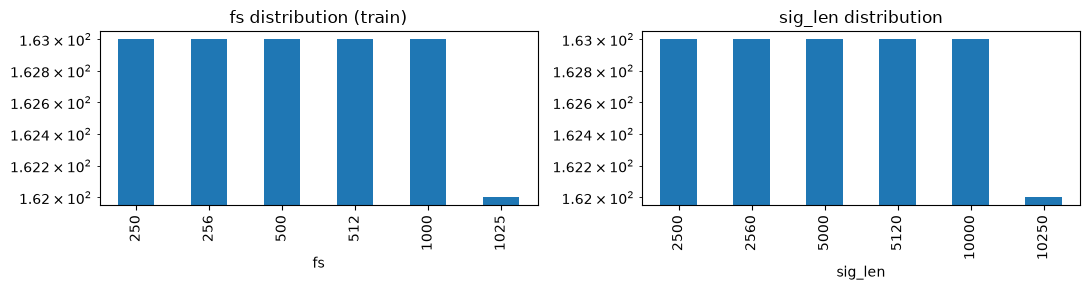

sig_len == 10*fs always: True


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
tr.fs.value_counts().sort_index().plot.bar(ax=ax[0], title="fs distribution (train)")
tr.sig_len.value_counts().sort_index().plot.bar(ax=ax[1], title="sig_len distribution")
for a in ax: a.set_yscale("log")
plt.tight_layout(); plt.show()
print("sig_len == 10*fs always:", bool((tr.sig_len == 10*tr.fs).all()))

## 2. Ground truth — one record, 12 leads
Each lead is its own 2.5 s series (lead II: 10 s). Lead layout note: the CSV stores the
12 leads in 2.5-second serialization blocks; `extract_lead_signal` handles that.
Also below: paper layout verification (rows [I,aVR,V1,V4]/[II,aVL,V2,V5]/[III,aVF,V3,V6]
+ full-width rhythm strip) — the constants the CellularVision baseline relies on.

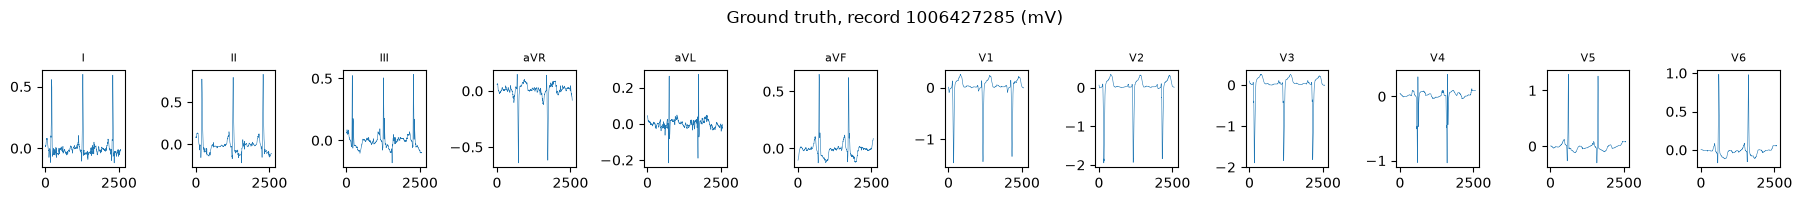

In [13]:
rec = 1006427285
gt = load_record_gt(DATA, rec)
fig, axes = plt.subplots(1, 12, figsize=(18, 2))
for i, c in enumerate(gt.columns):
    s = extract_lead_signal(gt, c)
    axes[i].plot(s[:2562], lw=0.4); axes[i].set_title(c, fontsize=8)
plt.suptitle(f"Ground truth, record {rec} (mV)"); plt.tight_layout(); plt.show()

## 3. The 9 imaging variants — same signal, deteriorations applied

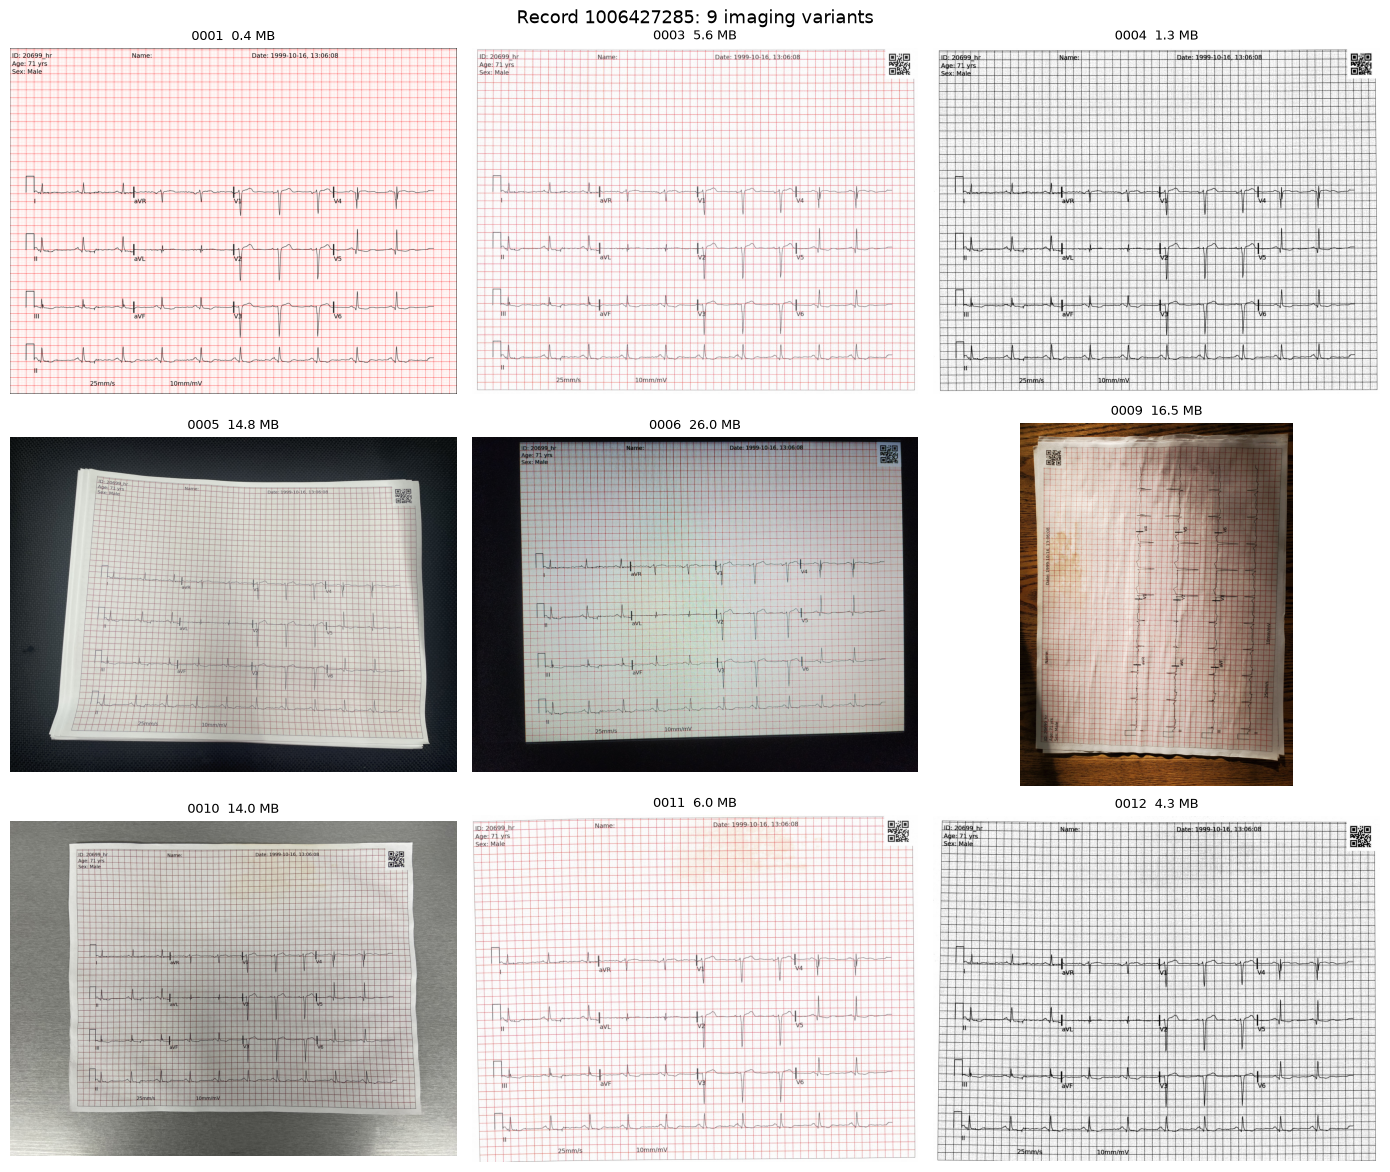

In [14]:
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for ax, v in zip(axes.ravel(), VARIANTS):
    p = f"{DATA}/train/{rec}/{rec}-{v}.png"
    ax.imshow(Image.open(p)); ax.set_title(f"{v}  {os.path.getsize(p)/1e6:.1f} MB", fontsize=9); ax.axis("off")
plt.suptitle(f"Record {rec}: 9 imaging variants", fontsize=13); plt.tight_layout(); plt.show()

## 4. Paper layout & calibration (verified)

In [15]:
im = np.asarray(Image.open(f"{DATA}/train/{rec}/{rec}-0001.png").convert("RGB"))
r, g, b = im[...,0].astype(int), im[...,1].astype(int), im[...,2].astype(int)
reddish = (r > g + 20) & (r > b + 20)
black = (im.mean(2) < 110) & ~reddish
def centroid(y0,y1,x0,x1):
    ys=[]
    for x in range(x0, x1):
        c = np.flatnonzero(black[y0:y1, x])
        ys.append(c.mean()+y0 if len(c) else np.nan)
    return np.asarray(ys)
xg, cellw, N = 118, 492, 2562
rows_y = [(628,824),(890,1146),(1195,1425),(1455,1664)]
gt_norm = {L: (lambda s: (s-s.mean())/(s.std()+1e-9))(extract_lead_signal(gt, L)) for L in gt.columns}
names = list(gt.columns)
for bi,(y0,y1) in enumerate(rows_y):
    row=[]
    for ci in range(4):
        ys = centroid(y0,y1,xg+ci*cellw, xg+(ci+1)*cellw)
        fin = np.flatnonzero(np.isfinite(ys))
        s = np.interp(np.linspace(0,1,N), fin/len(ys), ys[fin]); s=(s-s.mean())/(s.std()+1e-9)
        ccs = {L: abs(np.corrcoef(s, gt_norm[L][:N])[0,1]) for L in names}
        row.append(f"{max(ccs, key=ccs.get)}({max(ccs.values()):.2f})")
    print(f"row {chr(65+bi)}:", row)

row A: ['I(0.83)', 'aVR(0.51)', 'V1(0.95)', 'V4(0.72)']
row B: ['II(0.88)', 'V3(0.23)', 'V2(0.96)', 'V5(0.78)']
row C: ['III(0.65)', 'aVF(0.58)', 'V3(0.96)', 'V6(0.74)']
row D: ['II(0.37)', 'aVF(0.20)', 'V1(0.95)', 'V6(0.92)']


## 5. Baseline 1 — all zeros (~0 dB anchor)

In [16]:
val_ids = load_val_ids(30)      # fixed 30-record subset (record-level 90/10 split, seed 0)
have = [r for r in val_ids if os.path.exists(f"{DATA}/train/{r}/{r}.csv")]
ratios = []
for rec in have:
    g = load_record_gt(DATA, rec)
    ratios.append(record_linear_snr(g, {L: np.zeros(len(g[L].dropna())) for L in g.columns}, fs_of[str(rec)]))
print(f"records scored: {len(have)}")
print(f"BASELINE 1 (all zeros): {competition_score_from_linear(ratios):.3f} dB")

records scored: 30
BASELINE 1 (all zeros): 0.262 dB


## 6. Baseline 2 — classical CV digitization (no ML)
`src/baseline_cv.py`: grid autocorrelation → calibration (px/s, px/mV) → fixed-layout
cell extraction → per-column trace tracking → resample → official metric. Evaluated on
the same 30-record subset across **all 9 variants** (270 evaluations).

In [17]:
have_pngs = [r for r in val_ids if all(os.path.exists(f"{DATA}/train/{r}/{r}-{v}.png") for v in VARIANTS)]
print("records with full image set:", len(have_pngs))
df_cv = run_validation(have_pngs, out_csv="cv_scores.csv", verbose=False)
print(df_cv.groupby('variant').db.agg(['mean','min','max']).round(2).to_string())
print(f"\nBASELINE 2 (classical CV): {competition_score_from_linear(df_cv.ratio):.3f} dB")

records with full image set: 30
         mean    min    max
variant                    
0001     6.95  -5.25  15.35
0003    -4.72 -11.26   0.29
0004     0.18  -1.51   1.51
0005    -4.35 -14.14   0.84
0006    -6.61 -20.49   0.50
0009    -6.38 -13.18   0.28
0010    -5.13 -14.76   1.32
0011    -3.98 -10.04   0.70
0012     0.25   0.00   1.51

BASELINE 2 (classical CV): 1.022 dB


## 7. Results summary

In [18]:
summary = {
    "all-zeros": competition_score_from_linear(ratios),
    "classical CV": competition_score_from_linear(df_cv.ratio),
    "community pretrained (same cohort, reference)": 17.989,
}
print(f"{'baseline':46s} {'score (dB)':>10s}")
for k, v in summary.items(): print(f"{k:46s} {v:10.3f}")
print("\nreference only — competition winner 23.33 dB on the PRIVATE test set (different data)")

baseline                                       score (dB)
all-zeros                                           0.262
classical CV                                        1.022
community pretrained (same cohort, reference)      17.989

reference only — competition winner 23.33 dB on the PRIVATE test set (different data)


**Takeaways**
- Pure-geometry CV is *correct on clean scans* (up to +15 dB/record) but collapses on
real-world variants (168/270 records below the zeros floor) — quantifying exactly why
successful approaches begin with learned rectification.
- The all-zeros anchor sits at ≈ 0 dB: the metric's vertical-offset removal gives small
positive boosts (≤ +3.9 dB/record).
- Everything is scored with the official metric on a fixed record-level validation split.